# Additional analyses (revision, Bioengineering-4723886)

Additional analyses performed during the revision (November 2026), after the models of the paper had been locked. The results of the original analysis (`results_v2`) are read but never modified;
all new results are saved in a separate results folder.

| Step | What it does | GPU training? |
|---|---|---|
| 5 | Paired AUC differences with 95% CIs, smallest detectable difference, equivalence check | no |
| 6 | External pairwise comparisons (patient bootstrap, Holm) and Brier-score CIs | no |
| 7 | Calibration (intercept, slope, ECE, scaled Brier), prevalence-shift correction, score histograms | no |
| 8 | Recalibration repeated over 500 random patient splits | no |
| 9 | Near-duplicate audit repeated with DINOv2 and CLIP at several thresholds | no (feature extraction only) |
| 10 | Text-overlay detection (OCR) and masking test on the internal test set | no |
| 11-12 | ResNet50 without class weights; InceptionV3 at 299 x 299 | yes, about 1 hour |

**How to run:** Runtime -> Change runtime type -> T4 GPU, then Runtime -> Run all. Completed training runs are skipped when the notebook is re-run.
Each step saves its tables in the results folder; each step can be run independently.

## Step 1 - Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB


## Step 2 - Shared code and settings

In [ ]:
%%writefile /content/r2_common.py
# Shared code for this notebook and its training worker (written by the notebook)
import os, json, time, random, platform, warnings
import numpy as np, pandas as pd
import tensorflow as tf, keras
for _g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(_g, True)
from keras import layers, ops
from PIL import Image, ImageOps
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
warnings.filterwarnings("ignore", category=UserWarning); warnings.filterwarnings("ignore", category=RuntimeWarning)
tf.get_logger().setLevel("ERROR")
pd.set_option("display.width", 220, "display.max_columns", 40)

from pathlib import Path
PROJECT    = Path('/content/drive/MyDrive/oral project')
CLEAN_DIR  = PROJECT / 'oral_clean'
EXT_DIR    = PROJECT / 'external_piyarathne'
RESULTS_V2 = PROJECT / 'results_v2'            # original results: READ ONLY
RESULTS_R1 = PROJECT / 'results_reviewer1'     # runs of notebook 2 (read only, used if present)
OUT        = PROJECT / 'results_reviewer2'     # all new results go here

MODELS = ["ResNet50", "VGG16", "MobileNetV2", "DenseNet121", "EfficientNetB0", "Xception", "InceptionV3"]
PRIMARY_MODEL = "ResNet50"

# ---- protocol of the paper (do not change) ----
IMG_SIZE = int(os.environ.get('IMG_SIZE_OVERRIDE', 224))   # 224 as in the paper; 299 only for the InceptionV3 check
BATCH_SIZE = 16
HEAD_EPOCHS, HEAD_LR = 10, 1e-3
FT_EPOCHS,   FT_LR   = 40, 1e-5
FT_FRACTION = 0.30
DENSE_UNITS, DROPOUT = 256, 0.30
ES_PATIENCE, LR_PATIENCE, LR_FACTOR, MIN_LR = 5, 2, 0.5, 1e-7
THRESHOLD = 0.5
AUG = dict(flip="horizontal", rotation_deg=15, translation=0.10, zoom=0.10, brightness=0.10)

# ---- settings used only by the new experiments ----
SCRATCH_LR, SCRATCH_EPOCHS, SCRATCH_PATIENCE = 1e-4, 100, 10   # training from random weights needs more epochs
FROZEN_EPOCHS = 50                                            # frozen backbone: allow the head to converge fully
COLOR_AUG = dict(contrast=0.15, saturation=(0.40, 0.60), hue=0.03)   # mild colour jitter (Part C)

UNWEIGHTED_SEEDS = [0, 1, 2, 3, 4]      # ResNet50 with and without class weights
INCEPTION_SEEDS  = [0, 1, 2]            # InceptionV3 at its native 299 x 299

EXPERIMENTS = {
    "baseline":     dict(),                        # the paper's protocol
    "unweighted":   dict(class_weights=False),     # unweighted loss
    "inception299": dict(),                        # same protocol, input 299 x 299
}
LABELS = {"baseline": "Class-weighted loss (paper)", "unweighted": "Unweighted loss", "inception299": "InceptionV3 at 299 x 299"}

def run_dir(exp, name, seed):
    """Where a run lives: results_v2 (paper), results_reviewer1 or results_reviewer2."""
    if exp == "baseline" and seed <= 2:
        return RESULTS_V2 / "runs" / f"{name}_seed{seed}"
    if exp == "baseline" and (RESULTS_R1 / "runs" / "baseline" / f"{name}_seed{seed}" / "done.json").exists():
        return RESULTS_R1 / "runs" / "baseline" / f"{name}_seed{seed}"
    return OUT / "runs" / exp / f"{name}_seed{seed}"

JOBS_224 = [("baseline", PRIMARY_MODEL, s) for s in UNWEIGHTED_SEEDS if not (run_dir("baseline", PRIMARY_MODEL, s) / "done.json").exists()]
JOBS_224 += [("unweighted", PRIMARY_MODEL, s) for s in UNWEIGHTED_SEEDS]
JOBS_299 = [("inception299", "InceptionV3", s) for s in INCEPTION_SEEDS]

RUNS, TABLES, FIGS = OUT / "runs", OUT / "tables", OUT / "figures"
for p in (RUNS, TABLES, FIGS):
    p.mkdir(parents=True, exist_ok=True)

CACHE = Path(f"/content/r2_cache_{IMG_SIZE}")           # fast local copy of the image arrays (not on Drive)

def load_image(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)

def load_data():
    split = pd.read_csv(CLEAN_DIR / "split.csv")
    split["y"] = (split.label == "cancer").astype(int)
    split["path"] = [str(CLEAN_DIR / p) for p in split.clean_path]
    ext = pd.read_csv(EXT_DIR / "external.csv")
    ext["y"] = (ext.label == "cancer").astype(int)
    ext["path"] = [str(EXT_DIR / p) for p in ext.ext_path]
    frames = {n: split[split.split == n].reset_index(drop=True) for n in ("train", "val", "test")}
    frames["external"] = ext
    CACHE.mkdir(parents=True, exist_ok=True)
    out = {}
    for n, d in frames.items():
        f = CACHE / f"{n}.npy"
        if f.exists():
            X = np.load(f)
        else:
            X = np.stack([load_image(p) for p in d.path]); np.save(f, X)
        assert len(X) == len(d), "cache does not match the csv - delete /content/r1_cache and rerun"
        out[n] = dict(df=d, X=X, y=d.y.values)
    return out

DATA = load_data()

APPS = {"ResNet50": keras.applications.ResNet50, "VGG16": keras.applications.VGG16,
        "MobileNetV2": keras.applications.MobileNetV2, "DenseNet121": keras.applications.DenseNet121,
        "EfficientNetB0": keras.applications.EfficientNetB0, "Xception": keras.applications.Xception,
        "InceptionV3": keras.applications.InceptionV3}
PREP_MODE = {"ResNet50": "caffe", "VGG16": "caffe", "MobileNetV2": "tf", "DenseNet121": "torch",
             "EfficientNetB0": "none", "Xception": "tf", "InceptionV3": "tf"}

def preprocess(x, mode):
    if mode == "caffe":
        return ops.flip(x, axis=-1) - ops.convert_to_tensor([103.939, 116.779, 123.68])
    if mode == "tf":
        return x / 127.5 - 1.0
    if mode == "torch":
        return (x / 255.0 - ops.convert_to_tensor([0.485, 0.456, 0.406])) / ops.convert_to_tensor([0.229, 0.224, 0.225])
    return x

def augmenter(seed, kind="standard"):
    if kind == "none":
        return keras.Sequential([layers.Identity()], name="augmentation")
    blocks = [layers.RandomFlip(AUG["flip"], seed=seed),
              layers.RandomRotation(AUG["rotation_deg"] / 360.0, fill_mode="reflect", seed=seed),
              layers.RandomTranslation(AUG["translation"], AUG["translation"], fill_mode="reflect", seed=seed),
              layers.RandomZoom(AUG["zoom"], fill_mode="reflect", seed=seed),
              layers.RandomBrightness(AUG["brightness"], value_range=(0, 255), seed=seed)]
    if kind == "color":
        blocks += [layers.RandomContrast(COLOR_AUG["contrast"], seed=seed),
                   layers.RandomSaturation(COLOR_AUG["saturation"], value_range=(0, 255), seed=seed),
                   layers.RandomHue(COLOR_AUG["hue"], value_range=(0, 255), seed=seed),
                   layers.Lambda(lambda t: ops.clip(t, 0.0, 255.0), name="clip")]
    return keras.Sequential(blocks, name="augmentation")

NON_BACKBONE = {"augmentation", "preprocess"}

def build_model(name, seed, weights="imagenet", aug="standard"):
    keras.utils.set_random_seed(seed)
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = augmenter(seed, aug)(inp)
    x = layers.Lambda(lambda t: preprocess(t, PREP_MODE[name]), name="preprocess")(x)
    base = APPS[name](include_top=False, weights=weights, input_tensor=x)
    h = layers.GlobalAveragePooling2D(name="gap")(base.output)
    h = layers.Dropout(DROPOUT, name="drop1")(h)
    h = layers.Dense(DENSE_UNITS, activation="relu", name="dense")(h)
    h = layers.Dropout(DROPOUT, name="drop2")(h)
    out = layers.Dense(1, activation="sigmoid", name="prob")(h)
    model = keras.Model(inp, out, name=name)
    backbone = [l for l in base.layers if l.name not in NON_BACKBONE and not isinstance(l, keras.layers.InputLayer)]
    return model, backbone

def make_ds(X, y, training, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    if training:
        ds = ds.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def class_weights(y):
    n, pos = len(y), y.sum()
    return {0: n / (2 * (n - pos)), 1: n / (2 * pos)}

def callbacks(patience, lr_patience=LR_PATIENCE):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=LR_FACTOR, patience=lr_patience, min_lr=MIN_LR)]

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

def predict(model, X):
    return model.predict(X.astype("float32"), batch_size=32, verbose=0).ravel()

def save_preds(model, rdir):
    rows = []
    for part in ("val", "test", "external"):
        d = DATA[part]
        f = d["df"]["clean_path" if part != "external" else "ext_path"]
        g = d["df"]["patient_id"] if part == "external" else pd.Series([""] * len(f))
        rows.append(pd.DataFrame({"split": part, "file": f.values, "patient_id": g.values,
                                  "y": d["y"], "prob": predict(model, d["X"])}))
    pd.concat(rows).to_csv(rdir / "preds.csv", index=False)

def train_run(exp, name, seed):
    cfg = EXPERIMENTS[exp]
    rdir = RUNS / exp / f"{name}_seed{seed}"
    if (rdir / "done.json").exists():
        print(f"[skip] {exp} {name} seed {seed}"); return
    rdir.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    mode = cfg.get("mode", "two_stage")
    model, backbone = build_model(name, seed, weights=None if mode == "scratch" else "imagenet", aug=cfg.get("aug", "standard"))
    tr = make_ds(DATA["train"]["X"], DATA["train"]["y"], True, seed)
    va = make_ds(DATA["val"]["X"], DATA["val"]["y"], False, seed)
    cw = class_weights(DATA["train"]["y"]) if cfg.get("class_weights", True) else None
    hists = []

    if mode == "scratch":                                   # every layer (incl. BatchNorm) trained from random weights
        for l in backbone: l.trainable = True
        compile_model(model, SCRATCH_LR)
        h = model.fit(tr, validation_data=va, epochs=SCRATCH_EPOCHS, class_weight=cw,
                      callbacks=callbacks(SCRATCH_PATIENCE, 3), verbose=0)
        hists.append((1, h)); n_ft = len(backbone)
    else:                                                   # stage 1: backbone frozen, head trained
        for l in backbone: l.trainable = False
        compile_model(model, HEAD_LR)
        e1_max = FROZEN_EPOCHS if mode == "frozen" else cfg.get("head_epochs", HEAD_EPOCHS)
        h1 = model.fit(tr, validation_data=va, epochs=e1_max, class_weight=cw,
                       callbacks=callbacks(cfg.get("es_patience", ES_PATIENCE)), verbose=0)
        hists.append((1, h1)); n_ft = 0
        if mode != "frozen":                                # stage 2: fine-tune the top layers
            n_ft = int(round(len(backbone) * cfg.get("ft_fraction", FT_FRACTION)))
            for l in backbone[-n_ft:]:
                l.trainable = not isinstance(l, layers.BatchNormalization)
            compile_model(model, FT_LR)
            e1 = len(h1.epoch)
            h2 = model.fit(tr, validation_data=va, epochs=e1 + FT_EPOCHS, initial_epoch=e1, class_weight=cw,
                           callbacks=callbacks(cfg.get("es_patience", ES_PATIENCE)), verbose=0)
            hists.append((2, h2))

    parts, start = [], 0
    for stage, h in hists:
        n = len(h.epoch)
        parts.append(pd.DataFrame(h.history).assign(stage=stage, epoch=np.arange(start + 1, start + n + 1)))
        start += n
    hist = pd.concat(parts); hist.to_csv(rdir / "history.csv", index=False)
    model.save_weights(rdir / "best.weights.h5")
    save_preds(model, rdir)
    info = dict(experiment=exp, model=name, seed=seed, mode=mode, img_size=IMG_SIZE, class_weights=cw is not None,
                stage1_epochs=int((hist.stage == 1).sum()), stage2_epochs=int((hist.stage == 2).sum()),
                unfrozen_backbone_layers=int(n_ft), backbone_layers=len(backbone),
                trainable_params=int(sum(np.prod(w.shape) for w in model.trainable_weights)),
                minutes=round((time.time() - t0) / 60, 2), finished=time.strftime("%Y-%m-%d %H:%M:%S"))
    json.dump(info, open(rdir / "done.json", "w"), indent=2)
    print(f"[done] {exp:10s} {name:14s} seed {seed:2d} | epochs {info['stage1_epochs']}+{info['stage2_epochs']} | {info['minutes']} min")
    del model; keras.backend.clear_session()

def metrics(y, p, thr=THRESHOLD):
    yh = (p >= thr).astype(int)
    tn = int(((y == 0) & (yh == 0)).sum()); fp = int(((y == 0) & (yh == 1)).sum())
    fn = int(((y == 1) & (yh == 0)).sum()); tp = int(((y == 1) & (yh == 1)).sum())
    se = tp / (tp + fn); sp = tn / (tn + fp)
    return dict(auc=roc_auc_score(y, p), balanced_accuracy=(se + sp) / 2, sensitivity=se, specificity=sp,
                accuracy=(tp + tn) / len(y), brier=brier_score_loss(y, p))

Writing /content/r2_common.py


## Step 3 - Load shared code, data and the paper's locked predictions

In [ ]:
import sys, subprocess, shutil
sys.path.insert(0, "/content")
for m in [k for k in sys.modules if k == "r2_common"]: del sys.modules[m]
from r2_common import *
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "font.family": "DejaVu Sans"})

for p in (CLEAN_DIR / "split.csv", EXT_DIR / "external.csv", RESULTS_V2 / "lock.json", RESULTS_V2 / "external_predictions.csv"):
    print(p, "OK" if p.exists() else "NOT FOUND - check folder names")
summary = pd.DataFrame({k: {"images": len(v["y"]), "cancer": int(v["y"].sum()), "normal": int((1 - v["y"]).sum())}
                        for k, v in DATA.items()}).T
display(summary)
assert summary.loc["train", "images"] == 733 and summary.loc["test", "images"] == 156, "Partition differs from the paper!"

lock = json.load(open(RESULTS_V2 / "lock.json"))["locked_seed"]
y_test = DATA["test"]["y"]
P_TEST = {}
for m in MODELS:
    pr = pd.read_csv(RESULTS_V2 / "runs" / f"{m}_seed{lock[m]}" / "preds.csv"); t = pr[pr.split == "test"]
    assert (t.file.values == DATA["test"]["df"].clean_path.values).all()
    P_TEST[m] = t.prob.values
ext_pred = pd.read_csv(RESULTS_V2 / "external_predictions.csv")
y_ext, g_ext = ext_pred.y.values, ext_pred.patient_id.values
P_EXT = {m: ext_pred[m].values for m in MODELS}
PI_TRAIN, PI_EXT = DATA["train"]["y"].mean(), y_ext.mean()
print("Locked seeds:", lock)
print(f"Cancer prevalence: training {PI_TRAIN:.3f}, internal test {y_test.mean():.3f}, external {PI_EXT:.3f}")
for m in MODELS:
    print(f"{m:15s} internal AUC {roc_auc_score(y_test, P_TEST[m]):.3f} | external AUC {roc_auc_score(y_ext, P_EXT[m]):.3f}")

/content/drive/MyDrive/oral project/oral_clean/split.csv OK
/content/drive/MyDrive/oral project/external_piyarathne/external.csv OK
/content/drive/MyDrive/oral project/results_v2/lock.json OK
/content/drive/MyDrive/oral project/results_v2/external_predictions.csv OK


,images,cancer,normal
train,733,399,334
val,156,85,71
test,156,85,71
external,813,126,687


Locked seeds: {'VGG16': 1, 'ResNet50': 2, 'DenseNet121': 2, 'EfficientNetB0': 0, 'Xception': 1, 'MobileNetV2': 0, 'InceptionV3': 2}
Cancer prevalence: training 0.544, internal test 0.545, external 0.155
ResNet50        internal AUC 0.972 | external AUC 0.855
VGG16           internal AUC 0.975 | external AUC 0.855
MobileNetV2     internal AUC 0.967 | external AUC 0.820
DenseNet121     internal AUC 0.969 | external AUC 0.839
EfficientNetB0  internal AUC 0.961 | external AUC 0.858
Xception        internal AUC 0.966 | external AUC 0.824
InceptionV3     internal AUC 0.945 | external AUC 0.780


## Step 4 - Statistical helper functions

In [ ]:
N_BOOT = 2000

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return max(0.0, c - h), min(1.0, c + h)

def _midrank(x):
    J = np.argsort(x, kind="mergesort"); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(N); out[J] = T; return out

def delong_cov(y, preds):
    preds = np.atleast_2d(preds); y = np.asarray(y)
    order = np.argsort(-y, kind="mergesort"); P = preds[:, order]; m = int(y.sum()); n = len(y) - m
    tx = np.array([_midrank(r[:m]) for r in P]); ty = np.array([_midrank(r[m:]) for r in P]); tz = np.array([_midrank(r) for r in P])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1.0 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n

def delong_ci(y, p):
    auc, cov = delong_cov(y, p); se = np.sqrt(cov[0, 0])
    return max(0, auc[0] - 1.96 * se), min(1, auc[0] + 1.96 * se)

def holm(pvals):
    p = np.asarray(pvals, float); m = len(p); adj = np.empty(m); run = 0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def bal_acc(y, p, t=THRESHOLD):
    yh = p >= t
    return 0.5 * (((y == 1) & yh).sum() / (y == 1).sum() + ((y == 0) & ~yh).sum() / (y == 0).sum())

def cluster_indices(g):
    return list(pd.Series(np.arange(len(g))).groupby(np.asarray(g)).apply(np.array).values)

def boot_samples(n=None, groups=None, B=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    for _ in range(B):
        if groups is None:
            yield rng.integers(0, n, n)
        else:
            yield np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def calibration(y, p):
    x = logit(p)
    slope = LogisticRegression(C=1e10, max_iter=5000).fit(x[:, None], y).coef_[0, 0]
    a = 0.0                                                  # calibration-in-the-large (slope fixed at 1)
    for _ in range(100):
        mu = 1 / (1 + np.exp(-(a + x))); a += np.sum(y - mu) / np.sum(mu * (1 - mu))
    bins = np.minimum((p * 10).astype(int), 9)
    ece = sum(abs(p[bins == b].mean() - y[bins == b].mean()) * (bins == b).mean() for b in range(10) if (bins == b).any())
    brier = brier_score_loss(y, p); null = y.mean() * (1 - y.mean())
    return dict(brier=brier, null_brier=null, scaled_brier=1 - brier / null, cal_intercept=a, cal_slope=slope, ece=ece)

def prior_shift(p, pi_old, pi_new):
    r1, r0 = pi_new / pi_old, (1 - pi_new) / (1 - pi_old)
    return p * r1 / (p * r1 + (1 - p) * r0)

def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIGS / f"{name}.png", bbox_inches="tight"); fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)
print("helpers ready")

helpers ready


## Step 5 - Paired differences on the internal test set
For each comparator: AUC difference with its 95% CI (DeLong), z statistic, raw and Holm-adjusted p, the smallest AUC difference this test set could detect (80% power), and a paired bootstrap CI for the balanced-accuracy difference.
`Equivalent at ±0.05` = the 90% CI lies inside ±0.05 (two one-sided tests). The margin of 0.05 was not prespecified; this is a post hoc analysis.

In [ ]:
EQ_MARGIN = 0.05
rows, groups_none = [], None
for m in MODELS:
    if m == PRIMARY_MODEL: continue
    aucs, cov = delong_cov(y_test, np.vstack([P_TEST[PRIMARY_MODEL], P_TEST[m]]))
    d = aucs[0] - aucs[1]; se = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]); z = d / se
    bd = np.array([bal_acc(y_test[i], P_TEST[PRIMARY_MODEL][i]) - bal_acc(y_test[i], P_TEST[m][i])
                   for i in boot_samples(len(y_test)) if len(np.unique(y_test[i])) == 2])
    rows.append({"Comparator": m, "ΔAUC (ResNet50 − comparator)": round(d, 3),
                 "95% CI": f"{d - 1.96 * se:.3f} to {d + 1.96 * se:.3f}", "z": round(z, 2),
                 "p": 2 * stats.norm.sf(abs(z)), "Smallest detectable ΔAUC (80% power)": round(2.80 * se, 3),
                 f"Equivalent at ±{EQ_MARGIN}": (d - 1.645 * se > -EQ_MARGIN) and (d + 1.645 * se < EQ_MARGIN),
                 "Δ balanced accuracy": round(bal_acc(y_test, P_TEST[PRIMARY_MODEL]) - bal_acc(y_test, P_TEST[m]), 3),
                 "Δ bal. acc. 95% CI (bootstrap)": f"{np.percentile(bd, 2.5):.3f} to {np.percentile(bd, 97.5):.3f}"})
t1 = pd.DataFrame(rows); t1.insert(5, "p (Holm)", holm(t1.p)); t1["p"] = t1.p.round(3); t1["p (Holm)"] = t1["p (Holm)"].round(3)
t1.to_csv(TABLES / "R2c1_internal_paired_differences.csv", index=False)
display(t1)

,Comparator,ΔAUC (ResNet50 − comparator),95% CI,z,p,p (Holm),Smallest detectable ΔAUC (80% power),Equivalent at ±0.05,Δ balanced accuracy,Δ bal. acc. 95% CI (bootstrap)
0,VGG16,-0.002,-0.013 to 0.008,-0.45,0.656,1.000,0.016,True,0.021,-0.018 to 0.064
1,MobileNetV2,0.005,-0.014 to 0.025,0.56,0.575,1.000,0.027,True,0.025,-0.025 to 0.078
2,DenseNet121,0.004,-0.012 to 0.019,0.46,0.643,1.000,0.022,True,-0.003,-0.046 to 0.040
3,EfficientNetB0,0.011,-0.006 to 0.028,1.28,0.201,1.000,0.024,True,0.001,-0.043 to 0.046
4,Xception,0.007,-0.010 to 0.023,0.80,0.421,1.000,0.023,True,0.001,-0.046 to 0.047
5,InceptionV3,0.027,0.001 to 0.053,2.05,0.041,0.245,0.037,True,0.020,-0.030 to 0.072


## Step 6 - External pairwise comparisons and Brier-score confidence intervals

In [ ]:
G = cluster_indices(g_ext)
samples = [i for i in boot_samples(groups=G) if len(np.unique(y_ext[i])) == 2]
rows = []
for m in MODELS:
    if m == PRIMARY_MODEL: continue
    d0 = roc_auc_score(y_ext, P_EXT[PRIMARY_MODEL]) - roc_auc_score(y_ext, P_EXT[m])
    bd = np.array([roc_auc_score(y_ext[i], P_EXT[PRIMARY_MODEL][i]) - roc_auc_score(y_ext[i], P_EXT[m][i]) for i in samples])
    rows.append({"Comparator": m, "ΔAUC (ResNet50 − comparator)": round(d0, 3),
                 "95% CI (patient bootstrap)": f"{np.percentile(bd, 2.5):.3f} to {np.percentile(bd, 97.5):.3f}",
                 "p": min(1.0, 2 * min((bd <= 0).mean(), (bd >= 0).mean()))})
t12 = pd.DataFrame(rows); t12["p (Holm)"] = holm(t12.p).round(3); t12["p"] = t12.p.round(3)
t12.to_csv(TABLES / "R2c12_external_paired_auc.csv", index=False)
print(f"External image-level AUC differences ({len(samples)} patient-cluster bootstrap resamples)"); display(t12)

rows = []
for m in MODELS:
    bi = [brier_score_loss(y_test[i], P_TEST[m][i]) for i in boot_samples(len(y_test))]
    be = [brier_score_loss(y_ext[i], P_EXT[m][i]) for i in samples]
    rows.append({"Model": m, "Internal Brier": round(brier_score_loss(y_test, P_TEST[m]), 3),
                 "Internal 95% CI": f"{np.percentile(bi, 2.5):.3f}-{np.percentile(bi, 97.5):.3f}",
                 "External Brier": round(brier_score_loss(y_ext, P_EXT[m]), 3),
                 "External 95% CI (patient bootstrap)": f"{np.percentile(be, 2.5):.3f}-{np.percentile(be, 97.5):.3f}"})
tb = pd.DataFrame(rows); tb.to_csv(TABLES / "R2c12_brier_with_CI.csv", index=False)
print(f"Brier score. Reference ('no-skill', always predicting the prevalence): internal {y_test.mean() * (1 - y_test.mean()):.3f}, external {PI_EXT * (1 - PI_EXT):.3f}")
display(tb)

ci_methods = pd.DataFrame([
    ["Internal test (Table 7)", "Accuracy, sensitivity, specificity, PPV, NPV", "Wilson score"],
    ["Internal test (Table 7)", "AUC", "DeLong"],
    ["Internal test (Table 7)", "Balanced accuracy, F1, κ, Brier", "Percentile bootstrap, 2,000 resamples of images"],
    ["External, image level (Table 9)", "All metrics incl. AUC and Brier", "Percentile bootstrap, 2,000 resamples of patients (Wilson if no errors)"],
    ["External, patient level (Table 10)", "Proportions / AUC", "Wilson / DeLong (one score per patient)"],
    ["Recalibration (Table 11)", "All metrics", "Percentile bootstrap, 2,000 resamples of held-out patients"],
    ["Pairwise, internal (Table 8)", "ΔAUC / correctness", "DeLong test with CI / exact McNemar; Holm over 6 comparisons"],
    ["Pairwise, external (new)", "ΔAUC", "Patient-cluster bootstrap CI and p; Holm over 6 comparisons"]],
    columns=["Analysis", "Quantity", "Method"])
ci_methods.to_csv(TABLES / "R2c12_ci_methods_summary.csv", index=False); display(ci_methods)

External image-level AUC differences (2000 patient-cluster bootstrap resamples)


,Comparator,ΔAUC (ResNet50 − comparator),95% CI (patient bootstrap),p,p (Holm)
0,VGG16,0.000,-0.036 to 0.040,0.986,1.000
1,MobileNetV2,0.036,-0.008 to 0.084,0.115,0.545
2,DenseNet121,0.017,-0.013 to 0.049,0.280,0.840
3,EfficientNetB0,-0.003,-0.038 to 0.030,0.856,1.000
4,Xception,0.031,-0.007 to 0.074,0.109,0.545
5,InceptionV3,0.076,0.040 to 0.115,0.000,0.000


Brier score. Reference ('no-skill', always predicting the prevalence): internal 0.248, external 0.131


,Model,Internal Brier,Internal 95% CI,External Brier,External 95% CI (patient bootstrap)
0,ResNet50,0.066,0.038-0.098,0.451,0.408-0.494
1,VGG16,0.072,0.043-0.104,0.327,0.288-0.370
2,MobileNetV2,0.089,0.058-0.123,0.369,0.331-0.410
3,DenseNet121,0.071,0.043-0.103,0.375,0.337-0.414
4,EfficientNetB0,0.079,0.049-0.113,0.248,0.214-0.285
5,Xception,0.074,0.047-0.106,0.399,0.361-0.440
6,InceptionV3,0.086,0.056-0.118,0.477,0.437-0.517


,Analysis,Quantity,Method
0,Internal test (Table 7),"Accuracy, sensitivity, specificity, PPV, NPV",Wilson score
1,Internal test (Table 7),AUC,DeLong
2,Internal test (Table 7),"Balanced accuracy, F1, κ, Brier","Percentile bootstrap, 2,000 resamples of images"
3,"External, image level (Table 9)",All metrics incl. AUC and Brier,"Percentile bootstrap, 2,000 resamples of patie..."
4,"External, patient level (Table 10)",Proportions / AUC,Wilson / DeLong (one score per patient)
5,Recalibration (Table 11),All metrics,"Percentile bootstrap, 2,000 resamples of held-..."
6,"Pairwise, internal (Table 8)",ΔAUC / correctness,DeLong test with CI / exact McNemar; Holm over...
7,"Pairwise, external (new)",ΔAUC,Patient-cluster bootstrap CI and p; Holm over ...


## Step 7 - Prevalence versus calibration
* Specificity and sensitivity do not depend on prevalence; PPV, NPV and the Brier score do.
* **Prevalence-shift correction:** probabilities are re-weighted from the training prevalence to the external prevalence (Bayes' rule). If the specificity collapse were caused by prevalence alone, this correction would remove it. This uses the true external prevalence, so it is an explanatory analysis, not a deployable method.

cal_intercept: 0 = ideal (negative = probabilities too high); cal_slope: 1 = ideal (<1 = too extreme); scaled_brier: 1 = perfect, 0 = no better than the prevalence, <0 = worse


,Model,Set,brier,null_brier,scaled_brier,cal_intercept,cal_slope,ece,Specificity @0.5,Sensitivity @0.5,Normal images with p ≥ 0.9
0,ResNet50,Internal,0.066,0.248,0.735,-0.111,0.734,0.072,0.887,0.929,3 / 71
1,ResNet50,External,0.451,0.131,-2.440,-5.398,0.531,0.534,0.320,1.000,249 / 687
2,ResNet50,"External, prevalence-corrected",0.263,0.131,-1.006,-3.525,0.531,0.332,0.591,0.897,102 / 687


,Model,Set,brier,null_brier,scaled_brier,cal_intercept,cal_slope,ece,Specificity @0.5,Sensitivity @0.5,Normal images with p ≥ 0.9
0,ResNet50,Internal,0.066,0.248,0.735,-0.111,0.734,0.072,0.887,0.929,3 / 71
1,ResNet50,External,0.451,0.131,-2.440,-5.398,0.531,0.534,0.320,1.000,249 / 687
2,ResNet50,"External, prevalence-corrected",0.263,0.131,-1.006,-3.525,0.531,0.332,0.591,0.897,102 / 687
3,VGG16,Internal,0.072,0.248,0.711,0.724,0.654,0.069,0.915,0.859,2 / 71
4,VGG16,External,0.327,0.131,-1.500,-5.674,0.325,0.381,0.533,0.905,176 / 687
5,VGG16,"External, prevalence-corrected",0.209,0.131,-0.595,-3.800,0.320,0.233,0.716,0.810,85 / 687
6,MobileNetV2,Internal,0.089,0.248,0.643,1.206,0.814,0.075,0.944,0.824,1 / 71
7,MobileNetV2,External,0.369,0.131,-1.814,-4.585,0.468,0.443,0.438,0.929,187 / 687
8,MobileNetV2,"External, prevalence-corrected",0.215,0.131,-0.643,-2.711,0.468,0.241,0.694,0.794,66 / 687
9,DenseNet121,Internal,0.071,0.248,0.713,0.237,0.857,0.053,0.930,0.894,3 / 71


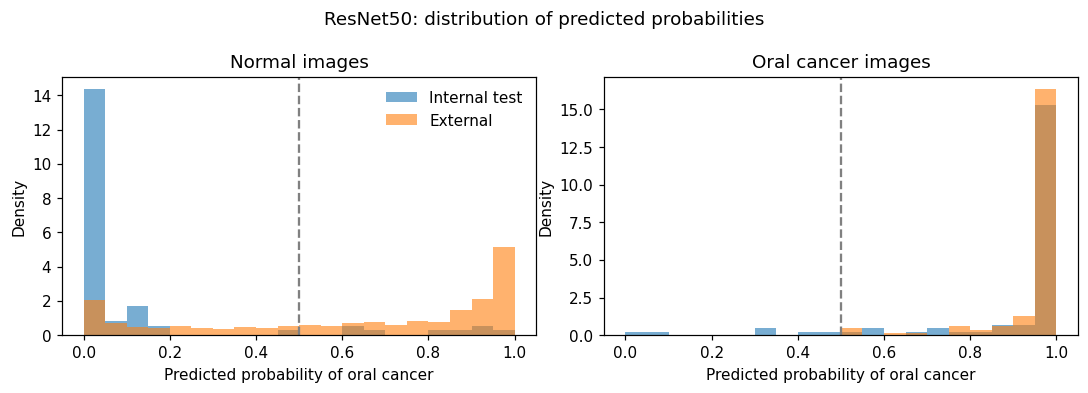

ResNet50: among 242 patients with only normal images, 83.5% have at least one false positive; 50.4% have ALL their images misclassified.
No site/location column in external.csv - site-level analysis skipped.


In [ ]:
rows = []
for m in MODELS:
    for setname, y, p in (("Internal", y_test, P_TEST[m]), ("External", y_ext, P_EXT[m]),
                          ("External, prevalence-corrected", y_ext, prior_shift(P_EXT[m], PI_TRAIN, PI_EXT))):
        c = calibration(y, p); yh = p >= THRESHOLD
        rows.append({"Model": m, "Set": setname, **{k: round(v, 3) for k, v in c.items()},
                     "Specificity @0.5": round(((y == 0) & ~yh).sum() / (y == 0).sum(), 3),
                     "Sensitivity @0.5": round(((y == 1) & yh).sum() / (y == 1).sum(), 3),
                     "Normal images with p ≥ 0.9": f"{((y == 0) & (p >= 0.9)).sum()} / {(y == 0).sum()}"})
t3 = pd.DataFrame(rows); t3.to_csv(TABLES / "R2c3_calibration_and_prevalence.csv", index=False)
print("cal_intercept: 0 = ideal (negative = probabilities too high); cal_slope: 1 = ideal (<1 = too extreme); scaled_brier: 1 = perfect, 0 = no better than the prevalence, <0 = worse")
display(t3[t3.Model == PRIMARY_MODEL]); display(t3)

# score distributions of NORMAL and CANCER images, internal vs external (primary model)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for a, cls, lab in ((ax[0], 0, "Normal images"), (ax[1], 1, "Oral cancer images")):
    a.hist(P_TEST[PRIMARY_MODEL][y_test == cls], bins=20, range=(0, 1), density=True, alpha=0.6, label="Internal test")
    a.hist(P_EXT[PRIMARY_MODEL][y_ext == cls], bins=20, range=(0, 1), density=True, alpha=0.6, label="External")
    a.axvline(THRESHOLD, ls="--", c="grey"); a.set_xlabel("Predicted probability of oral cancer"); a.set_ylabel("Density"); a.set_title(lab)
ax[0].legend(frameon=False)
fig.suptitle(f"{PRIMARY_MODEL}: distribution of predicted probabilities")
savefig(fig, "R2c3_score_distributions")

# are the external false positives spread over many normal patients or concentrated in a few?
d = pd.DataFrame({"pid": g_ext, "y": y_ext, "fp": (y_ext == 0) & (P_EXT[PRIMARY_MODEL] >= THRESHOLD)})
pn = d[d.y == 0].groupby("pid").agg(images=("fp", "size"), fps=("fp", "sum"))
pn = pn[d.groupby("pid").y.max().reindex(pn.index) == 0]
print(f"{PRIMARY_MODEL}: among {len(pn)} patients with only normal images, {(pn.fps > 0).mean():.1%} have at least one false positive; "
      f"{(pn.fps == pn.images).mean():.1%} have ALL their images misclassified.")

# specificity by intraoral site, if a site / location column is available
site_cols = [c for c in DATA["external"]["df"].columns if any(k in c.lower() for k in ("site", "location", "region", "area"))]
if site_cols:
    s = DATA["external"]["df"][site_cols[0]].values
    tab = pd.DataFrame({"site": s, "y": y_ext, "p": P_EXT[PRIMARY_MODEL]})
    tab = tab[tab.y == 0].groupby("site").p.agg(n="size", specificity=lambda v: (v < THRESHOLD).mean()).round(3)
    tab.to_csv(TABLES / "R2c3_specificity_by_site.csv"); display(tab)
else:
    print("No site/location column in external.csv - site-level analysis not possible.")

## Step 8 - How stable is the recalibrated threshold? (500 random patient splits)

Held-out results over 500 random 30/70 patient splits (target sensitivity 0.9 on the calibration part)


,threshold_median,threshold_2_5,threshold_97_5,heldout_sens_median,sens_2_5,sens_97_5,pct_splits_sens_ge_090,heldout_spec_median,spec_2_5,spec_97_5
model,,,,,,,,,,
ResNet50,0.885,0.669,0.964,0.896,0.736,0.988,47.4,0.599,0.439,0.787
VGG16,0.721,0.178,0.922,0.884,0.678,0.979,44.8,0.626,0.374,0.770
MobileNetV2,0.642,0.279,0.896,0.883,0.676,0.990,44.8,0.531,0.337,0.724
DenseNet121,0.696,0.365,0.913,0.893,0.665,0.989,45.4,0.560,0.300,0.797
EfficientNetB0,0.541,0.283,0.818,0.890,0.709,0.977,44.4,0.639,0.497,0.815
Xception,0.688,0.516,0.912,0.894,0.709,0.979,47.6,0.503,0.418,0.741
InceptionV3,0.764,0.404,0.893,0.894,0.736,0.984,47.0,0.470,0.224,0.642


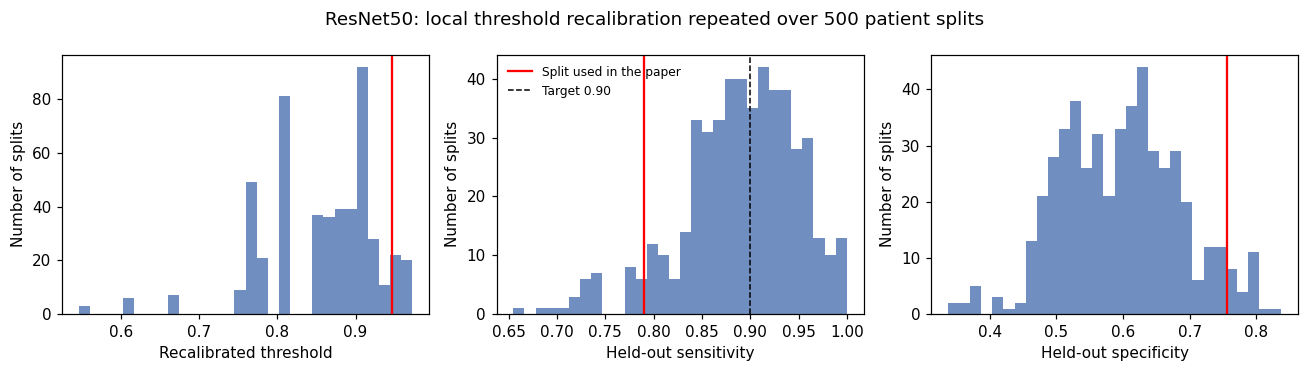

In [ ]:
CAL_FRACTION, TARGET_SENS, N_SPLITS, PAPER_SEED = 0.30, 0.90, 500, 2026
pat = pd.DataFrame({"pid": g_ext, "y": y_ext}).groupby("pid").y.max()

def split_patients(seed):
    rng = np.random.default_rng(seed); cal = []
    for cls in (0, 1):
        ids = np.array(pat[pat == cls].index, dtype=object); rng.shuffle(ids)
        cal += list(ids[:int(round(CAL_FRACTION * len(ids)))])
    return np.isin(g_ext, cal)

def thr_for_sens(y, p, target):
    pos = np.sort(p[y == 1])[::-1]
    return pos[int(np.ceil(target * len(pos))) - 1]

res = []
for s in [PAPER_SEED] + list(range(N_SPLITS)):
    cal = split_patients(s); tst = ~cal
    for m in MODELS:
        p = P_EXT[m]; t = thr_for_sens(y_ext[cal], p[cal], TARGET_SENS); yh = p[tst] >= t; y = y_ext[tst]
        res.append(dict(split=s, paper_split=(s == PAPER_SEED), model=m, threshold=t,
                        sensitivity=((y == 1) & yh).sum() / (y == 1).sum(), specificity=((y == 0) & ~yh).sum() / (y == 0).sum()))
res = pd.DataFrame(res); res.to_csv(TABLES / "R2c4_recalibration_500_splits_all.csv", index=False)
r = res[~res.paper_split]
t4 = r.groupby("model").agg(
    threshold_median=("threshold", "median"), threshold_2_5=("threshold", lambda v: v.quantile(.025)), threshold_97_5=("threshold", lambda v: v.quantile(.975)),
    heldout_sens_median=("sensitivity", "median"), sens_2_5=("sensitivity", lambda v: v.quantile(.025)), sens_97_5=("sensitivity", lambda v: v.quantile(.975)),
    pct_splits_sens_ge_090=("sensitivity", lambda v: 100 * (v >= TARGET_SENS).mean()),
    heldout_spec_median=("specificity", "median"), spec_2_5=("specificity", lambda v: v.quantile(.025)), spec_97_5=("specificity", lambda v: v.quantile(.975))
).reindex(MODELS).round(3)
t4.to_csv(TABLES / "R2c4_recalibration_500_splits_summary.csv")
print(f"Held-out results over {N_SPLITS} random 30/70 patient splits (target sensitivity {TARGET_SENS} on the calibration part)"); display(t4)

rp = r[r.model == PRIMARY_MODEL]; pp = res[res.paper_split & (res.model == PRIMARY_MODEL)].iloc[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, k, lab in zip(ax, ("threshold", "sensitivity", "specificity"), ("Recalibrated threshold", "Held-out sensitivity", "Held-out specificity")):
    a.hist(rp[k], bins=30, color="#4C72B0", alpha=0.8); a.axvline(pp[k], c="red", lw=1.5, label="Split used in the paper")
    if k == "sensitivity": a.axvline(TARGET_SENS, c="black", ls="--", lw=1, label="Target 0.90")
    a.set_xlabel(lab); a.set_ylabel("Number of splits")
ax[1].legend(frameon=False, fontsize=8)
fig.suptitle(f"{PRIMARY_MODEL}: local threshold recalibration repeated over {N_SPLITS} patient splits")
savefig(fig, "R2c4_recalibration_stability")

## Step 9 - Near-duplicate audit with independent feature extractors
Repeats the audit of Section 2.3 with **DINOv2** (self-supervised vision transformer) and **CLIP** (image-text model), which share nothing with the study CNNs, and with ResNet50 at several thresholds.
Similarity scales differ between extractors (CLIP similarities are generally higher), so the most similar pairs of each extractor are also shown for visual review.
The review figure contains external images and is used for internal review only; it is not published.

In [ ]:
import torch
from transformers import AutoImageProcessor, AutoModel, CLIPModel, CLIPProcessor
dev = "cuda" if torch.cuda.is_available() else "cpu"

def embed_torch(kind, X):
    if kind == "DINOv2":
        proc = AutoImageProcessor.from_pretrained("facebook/dinov2-base"); mdl = AutoModel.from_pretrained("facebook/dinov2-base").to(dev).eval()
        f = lambda inp: mdl(**inp).pooler_output
    else:
        proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32"); mdl = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
        def f(inp):
            r = mdl.get_image_features(pixel_values=inp["pixel_values"])
            return r if torch.is_tensor(r) else (getattr(r, "image_embeds", None) if getattr(r, "image_embeds", None) is not None else r.pooler_output)
    out = []
    with torch.no_grad():
        for i in range(0, len(X), 64):
            inp = proc(images=list(X[i:i + 64]), return_tensors="pt"); inp = {k: v.to(dev) for k, v in inp.items()}
            out.append(f(inp).float().cpu().numpy())
    del mdl; torch.cuda.empty_cache()
    E = np.concatenate(out); return E / np.linalg.norm(E, axis=1, keepdims=True)

def embed_resnet(X):
    fx = keras.applications.ResNet50(include_top=False, weights="imagenet", pooling="avg", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    E = np.concatenate([fx.predict(keras.applications.resnet50.preprocess_input(X[i:i + 64].astype("float32")), verbose=0)
                        for i in range(0, len(X), 64)])
    del fx; keras.backend.clear_session()
    return E / np.linalg.norm(E, axis=1, keepdims=True)

SETS = ("train", "val", "test", "external")
EMB = {"ResNet50 (paper)": {k: embed_resnet(DATA[k]["X"]) for k in SETS}}
for kind in ("DINOv2", "CLIP"):
    EMB[kind] = {k: embed_torch(kind, DATA[k]["X"]) for k in SETS}
for E in EMB.values():
    E["development"] = np.vstack([E["train"], E["val"], E["test"]])
XS = {k: DATA[k]["X"] for k in SETS}; XS["development"] = np.vstack([DATA["train"]["X"], DATA["val"]["X"], DATA["test"]["X"]])
YS = {k: DATA[k]["y"] for k in SETS}; YS["development"] = np.concatenate([DATA["train"]["y"], DATA["val"]["y"], DATA["test"]["y"]])

checks = [("val", "train"), ("test", "train"), ("test", "val"), ("external", "development")]
THRESHOLDS = [0.85, 0.90, 0.95, 0.98]
rows, top = [], {}
for ex, E in EMB.items():
    for q, ref in checks:
        S = E[q] @ E[ref].T; s = S.max(1); j = S.argmax(1)
        rows.append({"Extractor": ex, "Query": q, "Reference": ref, "Median max. similarity": round(float(np.median(s)), 3),
                     "Max. similarity": round(float(s.max()), 3), **{f"n ≥ {t}": int((s >= t).sum()) for t in THRESHOLDS},
                     "Label disagreements among top 10": int(sum(YS[q][i] != YS[ref][j[i]] for i in np.argsort(-s)[:10]))})
        top[(ex, q, ref)] = [(i, j[i], s[i]) for i in np.argsort(-s)[:6]]
t5 = pd.DataFrame(rows); t5.to_csv(TABLES / "R2c5_audit_three_extractors.csv", index=False); display(t5)

# visual review of the most similar pairs (REVIEW ONLY - contains external images, do not publish)
for ex in EMB:
    fig, ax = plt.subplots(len(checks), 6, figsize=(18, 2.6 * len(checks)))
    for r_, (q, ref) in enumerate(checks):
        for c_, (i, jj, s) in enumerate(top[(ex, q, ref)]):
            ax[r_, c_].imshow(np.concatenate([XS[q][i], XS[ref][jj]], axis=1)); ax[r_, c_].axis("off")
            ax[r_, c_].set_title(f"{q} vs {ref}  cos={s:.3f}", fontsize=8, color="red" if YS[q][i] != YS[ref][jj] else "black")
    fig.suptitle(f"{ex}: most similar pairs (left = query, right = nearest reference). REVIEW ONLY")
    fig.tight_layout(); fig.savefig(OUT / f"REVIEW_ONLY_top_pairs_{ex.split()[0]}.png", dpi=110); plt.show(); plt.close(fig)
print("Review figures saved (internal review only, not published).")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

... (18 outputs left out)

,Extractor,Query,Reference,Median max. similarity,Max. similarity,n ≥ 0.85,n ≥ 0.9,n ≥ 0.95,n ≥ 0.98,Label disagreements among top 10
0,ResNet50 (paper),val,train,0.802,0.944,32,7,0,0,0
1,ResNet50 (paper),test,train,0.806,0.949,33,7,0,0,1
2,ResNet50 (paper),test,val,0.767,0.882,7,0,0,0,0
3,ResNet50 (paper),external,development,0.764,0.880,5,0,0,0,5
4,DINOv2,val,train,0.890,0.966,115,62,5,0,0
5,DINOv2,test,train,0.893,0.982,114,68,5,1,1
6,DINOv2,test,val,0.869,0.982,97,41,3,1,0
7,DINOv2,external,development,0.892,0.958,621,333,9,0,4
8,CLIP,val,train,0.942,0.979,151,143,49,0,0
9,CLIP,test,train,0.938,0.985,152,141,48,3,2


[Figure removed from the public version of this notebook: it shows images from the restricted-access external dataset.]


[Figure removed from the public version of this notebook: it shows images from the restricted-access external dataset.]


[Figure removed from the public version of this notebook: it shows images from the restricted-access external dataset.]


ResNet50 (paper)  :   7 test images with a train/val match >= 0.9
DINOv2            :   8 test images with a train/val match >= 0.95
CLIP              :   7 test images with a train/val match >= 0.97
Excluded: 14 of 156 test images (4 cancer, 10 normal)


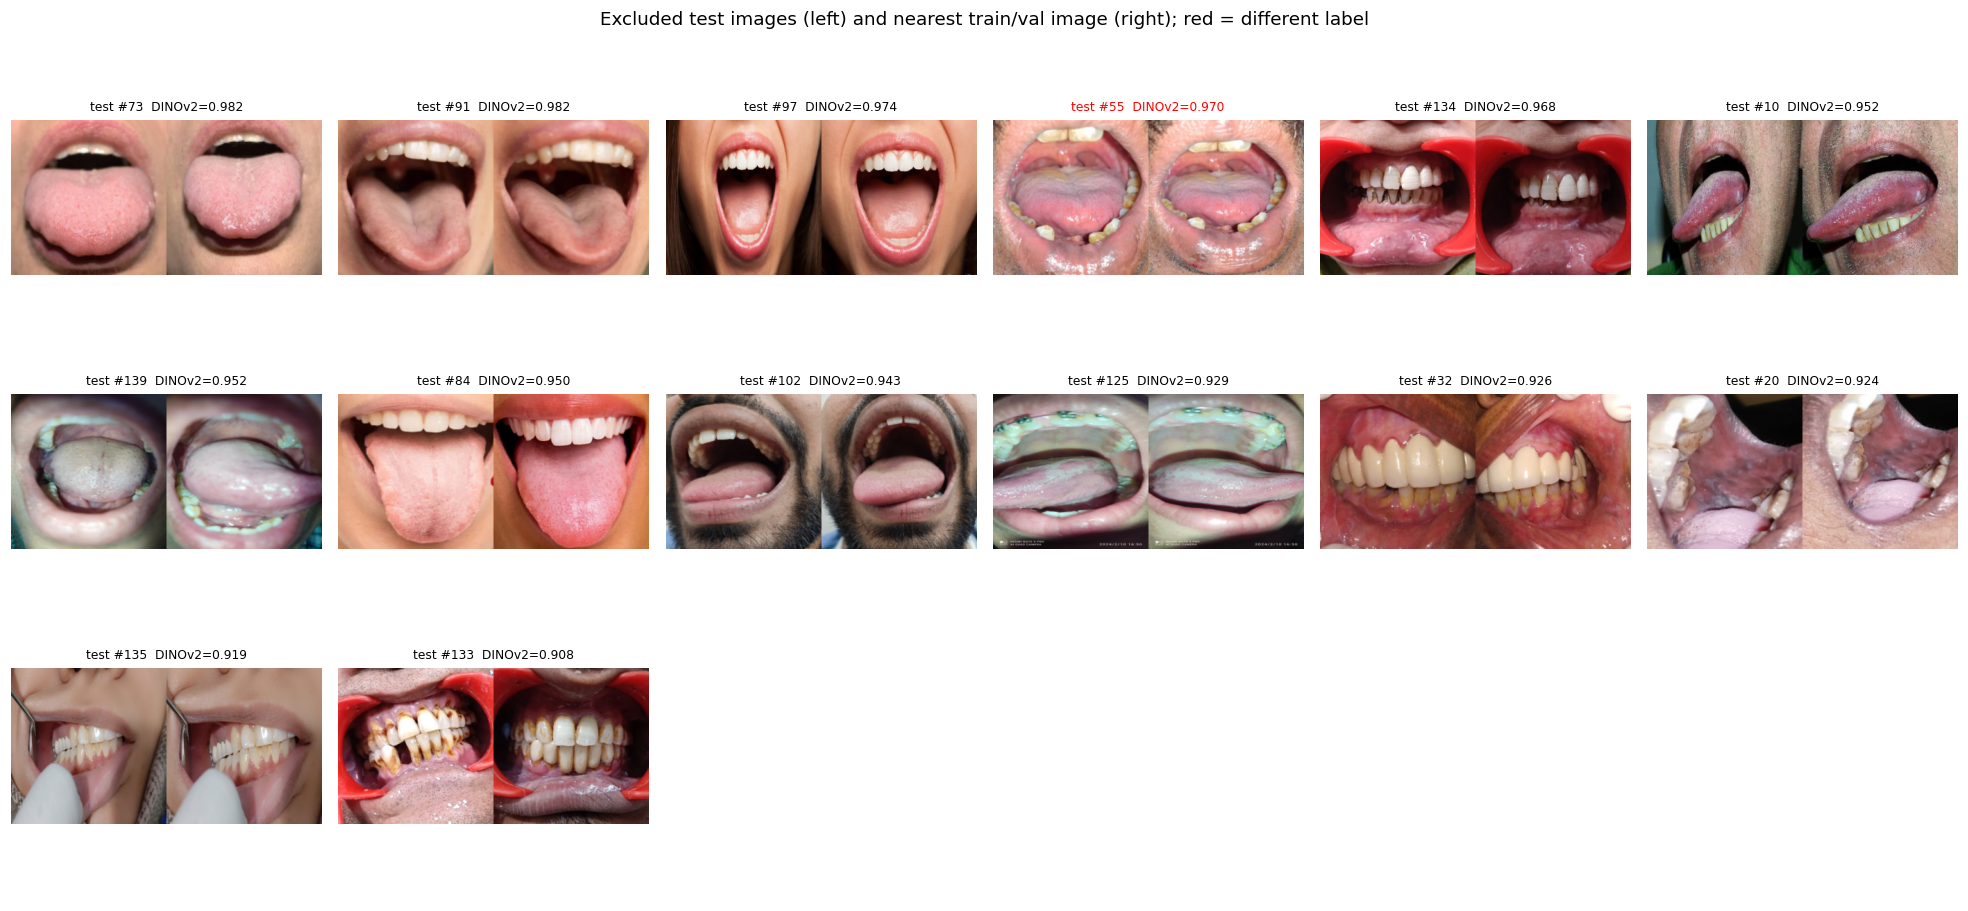

Internal test, all images vs without near-matched images (locked models)


,Model,"AUC, all 156","AUC, without 14 near-matched","Bal. acc., all","Bal. acc., without 14 near-matched","Sens., all","Sens., without 14 near-matched","Spec., all","Spec., without 14 near-matched"
0,ResNet50,0.972 (0.952-0.993),0.969 (0.946-0.992),0.908,0.897,0.929,0.926,0.887,0.869
1,VGG16,0.975 (0.956-0.994),0.970 (0.948-0.992),0.887,0.877,0.859,0.852,0.915,0.902
2,MobileNetV2,0.967 (0.943-0.991),0.967 (0.941-0.993),0.884,0.887,0.824,0.840,0.944,0.934
3,DenseNet121,0.969 (0.947-0.991),0.965 (0.940-0.990),0.912,0.903,0.894,0.889,0.930,0.918
4,EfficientNetB0,0.961 (0.934-0.989),0.954 (0.922-0.986),0.907,0.899,0.871,0.864,0.944,0.934
5,Xception,0.966 (0.941-0.990),0.964 (0.936-0.991),0.907,0.905,0.871,0.877,0.944,0.934
6,InceptionV3,0.945 (0.910-0.981),0.944 (0.906-0.982),0.888,0.883,0.918,0.914,0.859,0.852


ResNet50 - comparator on the reduced test set


,Comparator,ΔAUC,95% CI,p,p (Holm)
0,VGG16,-0.001,-0.013 to 0.011,0.874,1.000
1,MobileNetV2,0.002,-0.019 to 0.023,0.850,1.000
2,DenseNet121,0.004,-0.013 to 0.022,0.611,1.000
3,EfficientNetB0,0.015,-0.005 to 0.034,0.141,0.707
4,Xception,0.005,-0.013 to 0.024,0.556,1.000
5,InceptionV3,0.025,-0.002 to 0.052,0.071,0.428


ResNet50 - InceptionV3-299 (seed 0): ΔAUC 0.017 (95% CI -0.003 to 0.037), z = 1.65, DeLong p = 0.099


In [ ]:
# ===== Step 9b: internal-test sensitivity analysis without near-matched images =====
# Run after Step 9 in the same session (it uses the DINOv2/CLIP/ResNet50 embeddings).
# A test image is EXCLUDED if its most similar train/val image reaches the threshold of ANY extractor.
RULE = {"ResNet50 (paper)": 0.90, "DINOv2": 0.95, "CLIP": 0.97}

ref_X = np.vstack([DATA["train"]["X"], DATA["val"]["X"]])
ref_files = list(DATA["train"]["df"].clean_path) + list(DATA["val"]["df"].clean_path)
ref_y = np.concatenate([DATA["train"]["y"], DATA["val"]["y"]])
flag = np.zeros(len(y_test), bool)
lst = pd.DataFrame({"test_index": np.arange(len(y_test)), "test_file": DATA["test"]["df"].clean_path.values, "label": y_test})
for k, t in RULE.items():
    S = EMB[k]["test"] @ np.vstack([EMB[k]["train"], EMB[k]["val"]]).T
    s, j = S.max(1), S.argmax(1)
    lst[f"{k} sim"] = s.round(3); lst[f"{k} nearest"] = [ref_files[i] for i in j]; lst[f"{k} nearest_idx"] = j
    flag |= s >= t
    print(f"{k:18s}: {(s >= t).sum():3d} test images with a train/val match >= {t}")
lst["excluded"] = flag
lst.to_csv(TABLES / "R2c5_sensitivity_flagged_test_images.csv", index=False)
print(f"Excluded: {flag.sum()} of {len(flag)} test images ({int(y_test[flag].sum())} cancer, {int((1 - y_test[flag]).sum())} normal)")

# contact sheet of the excluded test images and their nearest train/val image (development images only)
show = lst[lst.excluded].sort_values("DINOv2 sim", ascending=False).head(30)
if len(show):
    n = len(show); cols = 6; rows = int(np.ceil(n / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(18, 2.8 * rows), squeeze=False)
    for a in axs.ravel(): a.axis("off")
    for a, (_, r) in zip(axs.ravel(), show.iterrows()):
        j = int(r["DINOv2 nearest_idx"])
        a.imshow(np.concatenate([DATA["test"]["X"][int(r.test_index)], ref_X[j]], axis=1))
        same_label = int(r.label) == int(ref_y[j])
        a.set_title(f"test #{int(r.test_index)}  DINOv2={r['DINOv2 sim']:.3f}", fontsize=8, color="black" if same_label else "red")
    fig.suptitle("Excluded test images (left) and nearest train/val image (right); red = different label")
    fig.tight_layout(); fig.savefig(FIGS / "R2c5_sensitivity_excluded_pairs.png", dpi=110); plt.show(); plt.close(fig)

def internal_row(name, p, keep):
    y = y_test[keep]; q = p[keep]; yh = q >= THRESHOLD
    lo, hi = delong_ci(y, q)
    se = ((y == 1) & yh).sum() / (y == 1).sum(); sp = ((y == 0) & ~yh).sum() / (y == 0).sum()
    return {"Model": name, "Images": int(keep.sum()), "AUC (95% CI)": f"{roc_auc_score(y, q):.3f} ({lo:.3f}-{hi:.3f})",
            "Sensitivity": round(se, 3), "Specificity": round(sp, 3), "Balanced accuracy": round((se + sp) / 2, 3)}

def analysis(keep, tag):
    rows = []
    for m in MODELS:
        full = internal_row(m, P_TEST[m], np.ones(len(y_test), bool)); red = internal_row(m, P_TEST[m], keep)
        rows.append({"Model": m, "AUC, all 156": full["AUC (95% CI)"], f"AUC, {tag}": red["AUC (95% CI)"],
                     "Bal. acc., all": full["Balanced accuracy"], f"Bal. acc., {tag}": red["Balanced accuracy"],
                     "Sens., all": full["Sensitivity"], f"Sens., {tag}": red["Sensitivity"],
                     "Spec., all": full["Specificity"], f"Spec., {tag}": red["Specificity"]})
    t = pd.DataFrame(rows)
    d = []
    for m in MODELS:
        if m == PRIMARY_MODEL: continue
        aucs, cov = delong_cov(y_test[keep], np.vstack([P_TEST[PRIMARY_MODEL][keep], P_TEST[m][keep]]))
        dd = aucs[0] - aucs[1]; s = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
        d.append({"Comparator": m, "ΔAUC": round(dd, 3), "95% CI": f"{dd - 1.96 * s:.3f} to {dd + 1.96 * s:.3f}",
                  "p": 2 * stats.norm.sf(abs(dd / s))})
    d = pd.DataFrame(d); d["p (Holm)"] = holm(d.p).round(3); d["p"] = d.p.round(3)
    return t, d

keep = ~flag
t_s, d_s = analysis(keep, f"without {int(flag.sum())} near-matched")
t_s.to_csv(TABLES / "R2c5_sensitivity_internal_metrics.csv", index=False); d_s.to_csv(TABLES / "R2c5_sensitivity_paired_auc.csv", index=False)
print("Internal test, all images vs without near-matched images (locked models)"); display(t_s)
print("ResNet50 - comparator on the reduced test set"); display(d_s)

# Optional stricter version: indices of test images confirmed visually as the same photograph
# (rotated / cropped / recoloured copy); empty = not used.
SAME_PHOTO = []
if SAME_PHOTO:
    keep2 = np.ones(len(y_test), bool); keep2[SAME_PHOTO] = False
    t2, d2 = analysis(keep2, f"without {len(SAME_PHOTO)} same-photo copies")
    t2.to_csv(TABLES / "R2c5_sensitivity_internal_metrics_same_photo.csv", index=False); display(t2); display(d2)

# InceptionV3 at 299 x 299 versus ResNet50 (locked models, all 156 internal-test images)
runs = []
for s in INCEPTION_SEEDS:
    rd = run_dir("inception299", "InceptionV3", s)
    if (rd / "done.json").exists():
        pr = pd.read_csv(rd / "preds.csv"); v, t = pr[pr.split == "val"], pr[pr.split == "test"]
        assert (t.file.values == DATA["test"]["df"].clean_path.values).all()
        runs.append((roc_auc_score(v.y, v.prob), s, t.prob.values))
if runs:
    _, s_best, p299 = max(runs)
    aucs, cov = delong_cov(y_test, np.vstack([P_TEST[PRIMARY_MODEL], p299]))
    dd = aucs[0] - aucs[1]; se_ = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    print(f"ResNet50 - InceptionV3-299 (seed {s_best}): ΔAUC {dd:.3f} (95% CI {dd - 1.96 * se_:.3f} to {dd + 1.96 * se_:.3f}), "
          f"z = {dd / se_:.2f}, DeLong p = {2 * stats.norm.sf(abs(dd / se_)):.3f}")

## Step 10 - Text overlays (possible shortcut) - detection and masking test
Text in each development image is detected with OCR (EasyOCR) at the original resolution. The table reports how often text occurs in each class.
Then the text regions of the internal-test images are covered with the image's median colour and the **locked ResNet50** is applied again:
if predictions change a lot, the model relies on the overlays. OCR finds printed text, not arrows or graphic marks, so this is a lower bound.

In [ ]:
!pip -q install easyocr
import easyocr
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)

def text_boxes(path, max_side=1000, min_conf=0.30):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
    W, H = im.size; sc = min(1.0, max_side / max(W, H)); small = im.resize((int(W * sc), int(H * sc)))
    boxes = []
    for pts, txt, conf in reader.readtext(np.asarray(small)):
        if conf >= min_conf and len(txt.strip()) >= 2:
            xs, ys = [p[0] / small.size[0] for p in pts], [p[1] / small.size[1] for p in pts]   # relative coordinates
            boxes.append((min(xs), min(ys), max(xs), max(ys), txt))
    return boxes

ocr = []
for part in ("train", "val", "test"):
    for k, path in enumerate(DATA[part]["df"].path):
        b = text_boxes(path)
        ocr.append(dict(split=part, idx=k, file=DATA[part]["df"].clean_path[k], y=int(DATA[part]["y"][k]),
                        has_text=len(b) > 0, n_boxes=len(b), text=" | ".join(x[4] for x in b), boxes=json.dumps([x[:4] for x in b])))
ocr = pd.DataFrame(ocr); ocr.to_csv(TABLES / "R2c5_ocr_text_detection.csv", index=False)

prev = ocr.groupby(["split", "y"]).has_text.agg(images="size", with_text="sum")
prev["percent"] = (100 * prev.with_text / prev.images).round(1)
prev = prev.rename(index={0: "normal", 1: "cancer"}, level=1); prev.to_csv(TABLES / "R2c5_text_prevalence_by_class.csv"); display(prev)
tr = ocr[ocr.split == "train"]; ct = pd.crosstab(tr.y, tr.has_text)
if ct.shape == (2, 2):
    print(f"Training set, text vs class: Fisher exact p = {stats.fisher_exact(ct.values)[1]:.4f}")

# masking test on the internal test set with the locked ResNet50
model, _ = build_model(PRIMARY_MODEL, lock[PRIMARY_MODEL], weights=None)
model.load_weights(RESULTS_V2 / "runs" / f"{PRIMARY_MODEL}_seed{lock[PRIMARY_MODEL]}" / "best.weights.h5")
Xm = DATA["test"]["X"].copy(); te = ocr[ocr.split == "test"].set_index("idx")
for k in range(len(Xm)):
    for x0, y0, x1, y1 in json.loads(te.loc[k, "boxes"]):
        a0, b0 = max(0, int(x0 * IMG_SIZE) - 3), max(0, int(y0 * IMG_SIZE) - 3)
        a1, b1 = min(IMG_SIZE, int(np.ceil(x1 * IMG_SIZE)) + 3), min(IMG_SIZE, int(np.ceil(y1 * IMG_SIZE)) + 3)
        Xm[k, b0:b1, a0:a1] = np.median(Xm[k].reshape(-1, 3), axis=0)
p0 = predict(model, DATA["test"]["X"]); p1 = predict(model, Xm)
del model; keras.backend.clear_session()
print("check: max difference from the stored predictions =", round(float(np.abs(p0 - P_TEST[PRIMARY_MODEL]).max()), 6))
ht = te.has_text.values
rows = []
for lab, mask in (("All test images", np.ones(len(ht), bool)), ("Test images with text", ht)):
    if mask.sum() == 0: continue
    yy = y_test[mask]
    rows.append({"Subset": lab, "Images": int(mask.sum()), "Cancer": int(yy.sum()),
                 "AUC original": round(roc_auc_score(yy, p0[mask]), 3) if len(np.unique(yy)) == 2 else np.nan,
                 "AUC masked": round(roc_auc_score(yy, p1[mask]), 3) if len(np.unique(yy)) == 2 else np.nan,
                 "Mean |Δp|": round(float(np.abs(p1 - p0)[mask].mean()), 3),
                 "Mean Δp (masked − original)": round(float((p1 - p0)[mask].mean()), 3),
                 "Predictions that flip at 0.5": int(((p0 >= .5) != (p1 >= .5))[mask].sum())})
t5b = pd.DataFrame(rows); t5b.to_csv(TABLES / "R2c5_text_masking_test.csv", index=False); display(t5b)

images  with_text  percent
split y                                 
test  normal      71          4      5.6
      cancer      85          4      4.7
train normal     334         15      4.5
      cancer     399         15      3.8
val   normal      71          2      2.8
      cancer      85          2      2.4

Training set, text vs class: Fisher exact p = 0.7091
check: max difference from the stored predictions = 3e-06


,Subset,Images,Cancer,AUC original,AUC masked,Mean |Δp|,Mean Δp (masked − original),Predictions that flip at 0.5
0,All test images,156,85,0.972,0.972,0.000,-0.000,0
1,Test images with text,8,4,1.000,1.000,0.006,-0.003,0


## Step 11 - Training runs (ResNet50 unweighted loss; InceptionV3 at 299 x 299), about 1 hour

In [ ]:
%%writefile /content/r2_worker.py
import sys
sys.path.insert(0, "/content")
from r2_common import train_run
args = sys.argv[1:]
for i in range(0, len(args), 3):
    train_run(args[i], args[i + 1], int(args[i + 2]))

Writing /content/r2_worker.py


In [ ]:
def run_jobs(jobs, img_size):
    pending = [j for j in jobs if not (run_dir(*j) / "done.json").exists()]
    print(f"[{img_size} px] {len(jobs) - len(pending)} runs already finished, {len(pending)} to go")
    env = dict(os.environ, IMG_SIZE_OVERRIDE=str(img_size))
    for k in range(0, len(pending), 4):
        chunk = pending[k:k + 4]
        r = subprocess.run([sys.executable, "/content/r2_worker.py", *[str(a) for j in chunk for a in j]],
                           capture_output=True, text=True, env=env)
        print("\n".join(l for l in r.stdout.splitlines() if l.startswith(("[done]", "[skip]"))))
        if r.returncode != 0:
            print("ERROR - last lines of the log:\n", "\n".join(r.stderr.splitlines()[-15:])); return False
    return True

t0 = time.time()
ok = run_jobs(JOBS_224, 224) and run_jobs(JOBS_299, 299)
print(f"Training finished in {(time.time() - t0) / 60:.0f} min" if ok else "Stopped because of an error (see above)")

[224 px] 0 runs already finished, 5 to go
[done] unweighted ResNet50       seed  0 | epochs 10+7 | 2.88 min
[done] unweighted ResNet50       seed  1 | epochs 10+8 | 2.13 min
[done] unweighted ResNet50       seed  2 | epochs 10+8 | 2.07 min
[done] unweighted ResNet50       seed  3 | epochs 10+11 | 2.35 min
[done] unweighted ResNet50       seed  4 | epochs 10+7 | 2.29 min
[299 px] 0 runs already finished, 3 to go
[done] inception299 InceptionV3    seed  0 | epochs 10+11 | 3.4 min
[done] inception299 InceptionV3    seed  1 | epochs 10+15 | 3.26 min
[done] inception299 InceptionV3    seed  2 | epochs 10+9 | 2.6 min
Training finished in 25 min


## Step 12 - Results of the training runs

In [ ]:
def ext_preds_for(exp, name, seed):
    # external probabilities of a run (computed from the checkpoint for paper runs, which did not store them)
    rd = run_dir(exp, name, seed); pr = pd.read_csv(rd / "preds.csv")
    if (pr.split == "external").any():
        return pr[pr.split == "external"].prob.values
    f = OUT / "v2_external" / f"{name}_seed{seed}.csv"; f.parent.mkdir(exist_ok=True)
    r1f = RESULTS_R1 / "baseline_v2_external" / f"{name}_seed{seed}.csv"
    if r1f.exists(): return pd.read_csv(r1f).prob.values
    if not f.exists():
        model, _ = build_model(name, seed, weights=None); model.load_weights(rd / "best.weights.h5")
        pd.DataFrame({"prob": predict(model, DATA["external"]["X"])}).to_csv(f, index=False)
        del model; keras.backend.clear_session()
    return pd.read_csv(f).prob.values

def run_metrics(exp, name, seed):
    rd = run_dir(exp, name, seed)
    if not (rd / "done.json").exists(): return None
    pr = pd.read_csv(rd / "preds.csv"); v, t = pr[pr.split == "val"], pr[pr.split == "test"]; pe = ext_preds_for(exp, name, seed)
    out = dict(experiment=exp, model=name, seed=seed, val_auc=roc_auc_score(v.y, v.prob))
    for tag, y, p in (("int", t.y.values, t.prob.values), ("ext", y_ext, pe)):
        yh = p >= THRESHOLD
        out.update({f"{tag}_auc": roc_auc_score(y, p), f"{tag}_sens": ((y == 1) & yh).sum() / (y == 1).sum(),
                    f"{tag}_spec": ((y == 0) & ~yh).sum() / (y == 0).sum(), f"{tag}_brier": brier_score_loss(y, p),
                    f"{tag}_mean_p_normal": p[y == 0].mean()})
        out[f"{tag}_balacc"] = (out[f"{tag}_sens"] + out[f"{tag}_spec"]) / 2
    return out, t.prob.values

def msd(x): x = pd.Series(x).dropna(); return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}" if len(x) > 1 else (f"{x.mean():.3f}" if len(x) else "")

# ---- class-weighted (paper) vs unweighted, ResNet50 ----
rows = [r[0] for e in ("baseline", "unweighted") for s in UNWEIGHTED_SEEDS if (r := run_metrics(e, PRIMARY_MODEL, s))]
CW = pd.DataFrame(rows); CW.to_csv(TABLES / "R2c6_class_weights_all_runs.csv", index=False)
cols = [("int_auc", "Internal AUC"), ("int_balacc", "Internal bal. acc."), ("int_sens", "Internal sens."), ("int_spec", "Internal spec."),
        ("ext_auc", "External AUC*"), ("ext_sens", "External sens.*"), ("ext_spec", "External spec.*"), ("ext_brier", "External Brier*"),
        ("ext_mean_p_normal", "Mean p on external normal images*")]
t6 = pd.DataFrame([{"Loss": LABELS[e], "Seeds": int((CW.experiment == e).sum()), **{lab: msd(CW[CW.experiment == e][c]) for c, lab in cols}}
                   for e in ("baseline", "unweighted")])
t6.to_csv(TABLES / "R2c6_class_weights_summary.csv", index=False)
print(f"Class weights used in the paper: normal {class_weights(DATA['train']['y'])[0]:.3f}, cancer {class_weights(DATA['train']['y'])[1]:.3f} (* exploratory)")
display(t6)

# ---- InceptionV3 at 299 x 299 vs 224 x 224 ----
rows, P299 = [], {}
for s in INCEPTION_SEEDS:
    r = run_metrics("inception299", "InceptionV3", s)
    if r: rows.append(r[0]); P299[s] = r[1]
I = pd.DataFrame(rows)
if len(I):
    best = int(I.sort_values("val_auc", ascending=False).seed.iloc[0]); p = P299[best]; yh = p >= THRESHOLD
    tn, fp, fn, tp = ((y_test == 0) & ~yh).sum(), ((y_test == 0) & yh).sum(), ((y_test == 1) & ~yh).sum(), ((y_test == 1) & yh).sum()
    aucs, cov = delong_cov(y_test, np.vstack([P_TEST[PRIMARY_MODEL], p])); d = aucs[0] - aucs[1]
    se = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    p224 = P_TEST["InceptionV3"]
    t8 = pd.DataFrame([
        {"Input": "224 x 224 (paper)", "Locked seed": lock["InceptionV3"], "AUC (95% CI)": f"{roc_auc_score(y_test, p224):.3f} ({delong_ci(y_test, p224)[0]:.3f}-{delong_ci(y_test, p224)[1]:.3f})",
         "Balanced accuracy": round(bal_acc(y_test, p224), 3), "Mean internal AUC over seeds": "see Table 6", "External AUC*": round(roc_auc_score(y_ext, P_EXT["InceptionV3"]), 3)},
        {"Input": "299 x 299 (native)", "Locked seed": best, "AUC (95% CI)": f"{roc_auc_score(y_test, p):.3f} ({delong_ci(y_test, p)[0]:.3f}-{delong_ci(y_test, p)[1]:.3f})",
         "Balanced accuracy": round(bal_acc(y_test, p), 3), "Mean internal AUC over seeds": msd(I.int_auc),
         "External AUC*": round(I[I.seed == best].ext_auc.iloc[0], 3)}])
    t8.to_csv(TABLES / "R2c8_inception_299.csv", index=False); display(t8)
    print(f"Locked InceptionV3-299: TN/FP/FN/TP = {tn}/{fp}/{fn}/{tp}. ResNet50 − InceptionV3-299: ΔAUC {d:.3f} "
          f"(95% CI {d - 1.96 * se:.3f} to {d + 1.96 * se:.3f}), DeLong p = {2 * stats.norm.sf(abs(d / se)):.3f}")
    I.to_csv(TABLES / "R2c8_inception_299_all_seeds.csv", index=False)

Class weights used in the paper: normal 1.097, cancer 0.919 (* exploratory)


,Loss,Seeds,Internal AUC,Internal bal. acc.,Internal sens.,Internal spec.,External AUC*,External sens.*,External spec.*,External Brier*,Mean p on external normal images*
0,Class-weighted loss (paper),5,0.971 ± 0.002,0.906 ± 0.006,0.911 ± 0.013,0.901 ± 0.017,0.861 ± 0.009,0.970 ± 0.020,0.406 ± 0.049,0.403 ± 0.034,0.579 ± 0.037
1,Unweighted loss,5,0.972 ± 0.002,0.906 ± 0.006,0.915 ± 0.015,0.896 ± 0.021,0.855 ± 0.007,0.983 ± 0.017,0.360 ± 0.050,0.427 ± 0.037,0.615 ± 0.037


,Input,Locked seed,AUC (95% CI),Balanced accuracy,Mean internal AUC over seeds,External AUC*
0,224 x 224 (paper),2,0.945 (0.910-0.981),0.888,see Table 6,0.780
1,299 x 299 (native),0,0.956 (0.926-0.986),0.891,0.955 ± 0.002,0.831


Locked InceptionV3-299: TN/FP/FN/TP = 63/8/9/76. ResNet50 − InceptionV3-299: ΔAUC 0.017 (95% CI -0.003 to 0.037), DeLong p = 0.099


## Step 13 - Zip tables and figures to download

In [ ]:
STAGE = OUT / "_download"; shutil.rmtree(STAGE, ignore_errors=True)
shutil.copytree(TABLES, STAGE / "tables"); shutil.copytree(FIGS, STAGE / "figures")
zip_path = shutil.make_archive(str(PROJECT / "reviewer2_results_tables_figures"), "zip", STAGE); shutil.rmtree(STAGE)
print("Download this file from Google Drive:", zip_path, "\n(The REVIEW_ONLY images are deliberately NOT in the zip: they contain external images.)")

Download this file from Google Drive: /content/drive/MyDrive/oral project/reviewer2_results_tables_figures.zip 
(The REVIEW_ONLY images are deliberately NOT in the zip: they contain external images.)
